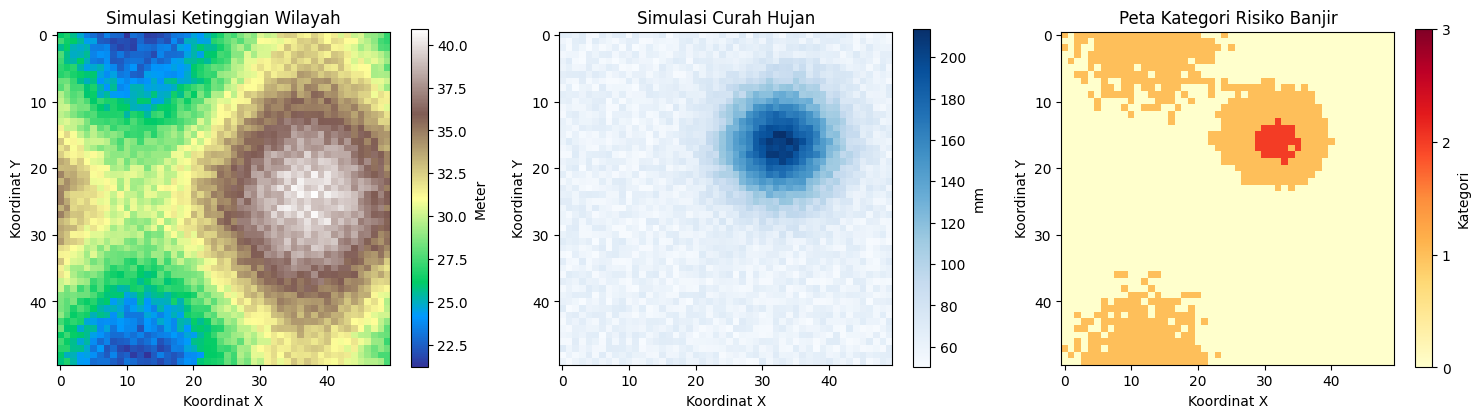

RINGKASAN ANALISIS RISIKO BANJIR
Risiko Rendah: 1926 titik (77.0%)
Risiko Sedang: 543 titik (21.7%)
Risiko Tinggi: 31 titik (1.2%)
Risiko Sangat Tinggi: 0 titik (0.0%)

REKOMENDASI
31 titik memiliki risiko tinggi atau sangat tinggi.
Wilayah tersebut dapat diprioritaskan untuk pemeriksaan lapangan dan kesiapan evakuasi.
1926 titik memiliki risiko rendah.

Catatan: hasil ini merupakan simulasi, bukan prediksi banjir nyata.


In [2]:

# IMPLEMENTASI HPC: SIMULASI RISIKO BANJIR
# Dataset: Data simulasi ketinggian dan curah hujan

import numpy as np
import matplotlib.pyplot as plt

# 1. MEMBUAT DATA SIMULASI
np.random.seed(42)

ukuran = 50
x, y = np.meshgrid(
    np.linspace(-3, 3, ukuran),
    np.linspace(-3, 3, ukuran)
)

# Simulasi ketinggian wilayah dalam meter
ketinggian = (
    30
    + 5 * np.sin(x)
    + 4 * np.cos(y)
    + 2 * np.random.random((ukuran, ukuran))
)

# Simulasi curah hujan dalam mm
curah_hujan = (
    50
    + 150 * np.exp(-((x - 1)**2 + (y + 1)**2))
    + 20 * np.random.random((ukuran, ukuran))
)

# 2. ANALISIS RISIKO BANJIR
# Hujan tinggi dan wilayah rendah diasumsikan
# memiliki risiko banjir lebih besar.

hujan_normal = (
    (curah_hujan - curah_hujan.min())
    / (curah_hujan.max() - curah_hujan.min())
)

elevasi_normal = (
    (ketinggian - ketinggian.min())
    / (ketinggian.max() - ketinggian.min())
)

risiko = 0.6 * hujan_normal + 0.4 * (1 - elevasi_normal)

# Kategori risiko simulasi
kategori = np.zeros_like(risiko, dtype=int)
kategori[risiko >= 0.35] = 1
kategori[risiko >= 0.60] = 2
kategori[risiko >= 0.80] = 3

# 3. MENAMPILKAN HASIL ANALISIS
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

gambar1 = axes[0].imshow(ketinggian, cmap="terrain")
axes[0].set_title("Simulasi Ketinggian Wilayah")
plt.colorbar(gambar1, ax=axes[0], label="Meter")

gambar2 = axes[1].imshow(curah_hujan, cmap="Blues")
axes[1].set_title("Simulasi Curah Hujan")
plt.colorbar(gambar2, ax=axes[1], label="mm")

gambar3 = axes[2].imshow(
    kategori, cmap="YlOrRd", vmin=0, vmax=3
)
axes[2].set_title("Peta Kategori Risiko Banjir")
plt.colorbar(
    gambar3,
    ax=axes[2],
    ticks=[0, 1, 2, 3],
    label="Kategori"
)

for ax in axes:
    ax.set_xlabel("Koordinat X")
    ax.set_ylabel("Koordinat Y")

plt.tight_layout()
plt.show()

# 4. RINGKASAN HASIL
nama_kategori = [
    "Rendah", "Sedang", "Tinggi", "Sangat Tinggi"
]

print("RINGKASAN ANALISIS RISIKO BANJIR")

for i, nama in enumerate(nama_kategori):
    jumlah = np.sum(kategori == i)
    persentase = jumlah / kategori.size * 100

    print(
        f"Risiko {nama}: {jumlah} titik "
        f"({persentase:.1f}%)"
    )

# 5. REKOMENDASI PRIORITAS
jumlah_tinggi = np.sum(kategori >= 2)
jumlah_rendah = np.sum(kategori == 0)

print("\nREKOMENDASI")
print(
    f"{jumlah_tinggi} titik memiliki risiko tinggi "
    "atau sangat tinggi."
)
print(
    "Wilayah tersebut dapat diprioritaskan untuk "
    "pemeriksaan lapangan dan kesiapan evakuasi."
)
print(
    f"{jumlah_rendah} titik memiliki risiko rendah."
)

print(
    "\nCatatan: hasil ini merupakan simulasi, "
    "bukan prediksi banjir nyata."
)
